# Lap5–7 Query-Demo: two-camera fusion (fr + rl) vs three-camera fusion

**Kernel:** `pixel-racers`

Extended from `lap3_ekf_2cam_fr_rl_query_demo.ipynb`: run fr+rl simulation for **Lap 5 / 6 / 7** each and compare against three-camera offline fusion. Map remains Lap2+4 (`map_*_lap2+4`).

| Mode | Description |
|---|---|
| **A** `se_predict` | SE dead reckoning; sample at two-camera \(t_{last}\) |
| **fused_se2_2cam** | fr+rl offline se2 |
| **fused_se2_3cam** | r+fr+rl offline se2 |
| **B** `ekf_cam_2cam` | fr/rl sync → se2 → EKF（\(R(s)\)） |

Visual observations: `outputs_hfnet_multi_lap_s/loc_lap{N}_{r,fr,rl}`. If missing, run §0 first.


In [1]:
from __future__ import annotations

import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

HERE = Path.cwd().resolve()
if HERE.name != "query-demo":
    HERE = HERE / "query-demo" if (HERE / "query-demo").is_dir() else HERE
ROOT = HERE.parent if HERE.name == "query-demo" else HERE
sys.path.insert(0, str(HERE))
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "3d-map-test"))

import query_demo_ekf as qde
from query_demo_ekf import (
    NoiseCfg,
    build_sync_buckets,
    ensure_paths,
    fuse_loc_tables_se2,
    interp_gt,
    load_cam_loc_tables,
    load_lap_window,
    load_racing_line,
    load_track_bounds,
    metrics_vs_gt,
    read_csv_ns,
    run_evaluate,
    run_mode_a_se_predict,
    run_mode_b_ekf,
    write_gt_lap_slice,
    write_process_noise_yaml,
    write_submission,
)
from ensure_lap_query import ensure_lap_loc

ensure_paths()
from obs_error_sigma_s import load_params, sigma_of_s

LAPS = (5, 6, 7)
CAMS_2 = ("fr", "rl")
CAMS_3 = ("r", "fr", "rl")
REF2 = "fr"
OUT_ROOT = HERE / "outputs" / "lap5_7_2cam_fr_rl"
OUT_ROOT.mkdir(parents=True, exist_ok=True)

print("ROOT", ROOT)
print("OUT_ROOT", OUT_ROOT)
print("LAPS", LAPS, "CAMS_2", CAMS_2)


ROOT /Users/hbai/SchubKI/PixelRacers
OUT_ROOT /Users/hbai/SchubKI/PixelRacers/query-demo/outputs/lap5_7_2cam_fr_rl
LAPS (5, 6, 7) CAMS_2 ('fr', 'rl')


## 0. Ensure `loc_lap{5,6,7}_{r,fr,rl}` exist (run SfM query if missing; slow)


In [2]:
for lap in LAPS:
    info = ensure_lap_loc(lap, cameras=CAMS_3)
    print(lap, "skipped" if info.get("skipped") else "ran", info.get("paths") or f"done query lap {lap}")


/Users/hbai/SchubKI/PixelRacers/pixel-racers/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


5 skipped {'r': '/Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs_hfnet_multi_lap_s/loc_lap5_r/errors.csv', 'fr': '/Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs_hfnet_multi_lap_s/loc_lap5_fr/errors.csv', 'rl': '/Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs_hfnet_multi_lap_s/loc_lap5_rl/errors.csv'}
6 skipped {'r': '/Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs_hfnet_multi_lap_s/loc_lap6_r/errors.csv', 'fr': '/Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs_hfnet_multi_lap_s/loc_lap6_fr/errors.csv', 'rl': '/Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs_hfnet_multi_lap_s/loc_lap6_rl/errors.csv'}
device mps backend sp_nv_nn proxy True

CAMERA r query_lap 7
[r] no ego polygons — full frame features
[r] LOAD map /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs_hfnet_multi_lap_s/map_r_lap2+4/map_bundle.npz
[r] LOAD query /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs_hfnet_multi_lap_s/loc_lap7_r/errors.csv 
[r] success=884/1095  A-RMSE=3.894

CAMERA fr qu

load camera_rl:   0%|          | 0/1095 [00:00<?, ?frm/s]

[rl] query extract 1095 in 55.6s


feat-qry-rl:   0%|          | 0/1095 [00:00<?, ?frm/s]

[rl] query features 351.9s


loc-rl:   0%|          | 0/1095 [00:00<?, ?qry/s]

[rl 0] ok=True corr=330 inl=56 err=0.3003367392711558
[rl 1] ok=True corr=345 inl=43 err=0.3223240695245891
[rl 2] ok=True corr=330 inl=94 err=0.1051910356360723
[rl 3] ok=True corr=330 inl=54 err=0.1984160665550003
[rl 4] ok=True corr=344 inl=64 err=0.06990530291541078
[rl 5] ok=True corr=323 inl=73 err=0.31810352074135434
[rl 6] ok=True corr=345 inl=109 err=0.011663158120398656
[rl 7] ok=True corr=307 inl=82 err=0.16318386129251125
[rl 8] ok=True corr=210 inl=52 err=0.16750297921608837
[rl 9] ok=True corr=305 inl=78 err=0.09261446017790498
[rl 49] ok=True corr=543 inl=134 err=0.14360052227845077
[rl 99] ok=True corr=109 inl=15 err=0.2061479174273724
[rl 149] ok=True corr=120 inl=25 err=0.27447260407039203
[rl 199] ok=True corr=142 inl=37 err=0.3860253009430825
[rl 249] ok=True corr=70 inl=18 err=1.0138493375047464
[rl 299] ok=True corr=23 inl=13 err=1.033896047673237
[rl 349] ok=True corr=58 inl=18 err=0.15828734176401174
[rl 399] ok=True corr=115 inl=36 err=0.4174213784222271
[rl 44

## 1. Process noise + shared resources (SE/GT/σ(s)/track)


In [3]:
cfg_dict = write_process_noise_yaml()
cfg = NoiseCfg.from_dict(cfg_dict)
print(json.dumps({k: cfg_dict[k] for k in (
    "sigma_vx_mps", "sigma_vy_mps", "sigma_ax_mps2", "sigma_ay_mps2", "sigma_wz_radps"
)}, indent=2))

se_all = read_csv_ns(qde.EXTRACTED / "state_estimation.csv")
gt_all = read_csv_ns(qde.EXTRACTED / "gt.csv")
load_params()
track_left, track_right = load_track_bounds()
track_line = load_racing_line()["track"]
print("SE", len(se_all), "GT", len(gt_all), "track lap m", float(track_line.lap))


{
  "sigma_vx_mps": 0.07291625677170689,
  "sigma_vy_mps": 0.020390247216390003,
  "sigma_ax_mps2": 10.591458770185817,
  "sigma_ay_mps2": 8.62517353987282,
  "sigma_wz_radps": 0.0031257765394782804
}
SE 126574 GT 126680 track lap m 2976.875276595886


## 2. Per lap: Mode A / 2cam & 3cam fusion / EKF(2cam)


In [4]:
METRIC_COLS = [
    "lap", "mode", "n_query", "n_success", "success_rate_%",
    "pos_rmse_xy_m", "lat_rmse_m", "lon_rmse_m", "pos_rmse_sn_m",
    "s_rmse_m", "n_rmse_m", "yaw_rmse_deg", "within_1m_%",
    "pos_median_m", "pos_p95_m",
]

def metrics_from_fuse_df(df: pd.DataFrame) -> tuple[dict, np.ndarray]:
    ok = df["ok"].astype(bool).to_numpy()
    met = qde.compute_camloc_metrics(
        stamps_ns=df["stamp_ns"].to_numpy(),
        gt_xy=np.column_stack([df["gt_x"], df["gt_y"]]),
        gt_yaw=df["gt_yaw"].to_numpy(float),
        pred_xy=np.column_stack([df["pred_x"], df["pred_y"]]),
        pred_yaw=df["pred_yaw"].to_numpy(float),
        ok=ok,
    )
    return met, ok


def run_one_lap(lap: int) -> pd.DataFrame:
    out = OUT_ROOT / f"lap{lap}"
    out_a, out_b = out / "se_predict", out / "ekf_cam_2cam"
    out_f2, out_f3, out_c = out / "fused_se2_2cam", out / "fused_se2_3cam", out / "compare"
    for d in (out_a, out_b, out_f2, out_f3, out_c, out_b / "sim"):
        d.mkdir(parents=True, exist_ok=True)

    start_ns, end_ns, lap_row = load_lap_window(lap)
    print(f"\n===== LAP {lap} duration={lap_row['duration_s']:.2f}s =====")
    se = se_all[(se_all.timestamp_ns >= start_ns) & (se_all.timestamp_ns <= end_ns)].reset_index(drop=True)
    x0, y0, yaw0 = float(se.iloc[0].x), float(se.iloc[0].y), float(se.iloc[0].yaw)
    t0 = int(se.iloc[0].timestamp_ns)

    tables_3 = load_cam_loc_tables(CAMS_3, qde.SFM_OUT, query_lap=lap)
    tables_2 = {c: tables_3[c] for c in CAMS_2}
    for c, df in tables_3.items():
        print(f"  loc_lap{lap}_{c}: n={len(df)} ok={df.ok.mean()*100:.1f}%")
    buckets_2 = build_sync_buckets(tables_2, ref_camera=REF2, cams=CAMS_2)
    gt_lap = write_gt_lap_slice(gt_all, start_ns, end_ns, out / f"gt_lap{lap}.csv")

    # Mode A
    pred_a = run_mode_a_se_predict(se, buckets_2, x0=x0, y0=y0, yaw0=yaw0)
    gt_a = interp_gt(gt_all, pred_a.timestamp_ns.to_numpy())
    err_a = np.hypot(pred_a.x - gt_a.x, pred_a.y - gt_a.y)
    yaw_a = np.degrees(np.arctan2(np.sin(pred_a.yaw - gt_a.yaw), np.cos(pred_a.yaw - gt_a.yaw)))
    write_submission(pred_a, out_a / "submission.csv")
    met_a = metrics_vs_gt(pred_a, gt_a)
    print("  A", run_evaluate(out_a / "submission.csv", gt_lap).splitlines()[2])

    # Mode B 2cam
    pred_b, sim_b = run_mode_b_ekf(
        se, buckets_2, cfg,
        x0=x0, y0=y0, yaw0=yaw0, t0_ns=t0,
        sigma_of_s_fn=sigma_of_s, track_line=track_line, cams=CAMS_2,
    )
    gt_b = interp_gt(gt_all, pred_b.timestamp_ns.to_numpy())
    err_b = np.hypot(pred_b.x - gt_b.x, pred_b.y - gt_b.y)
    yaw_b = np.degrees(np.arctan2(np.sin(pred_b.yaw - gt_b.yaw), np.cos(pred_b.yaw - gt_b.yaw)))
    write_submission(pred_b, out_b / "submission.csv")
    sim_b.to_csv(out_b / "sim" / "ekf_sim.csv", index=False)
    met_b = metrics_vs_gt(pred_b, gt_b)
    print("  B", run_evaluate(out_b / "submission.csv", gt_lap).splitlines()[2],
          f"update={sim_b.updated.mean()*100:.1f}%")

    # fuse
    df_f2 = fuse_loc_tables_se2(tables_2, ref_camera=REF2)
    df_f3 = fuse_loc_tables_se2(tables_3, ref_camera="r")
    df_f2.to_csv(out_f2 / "errors_se2.csv", index=False)
    df_f3.to_csv(out_f3 / "errors_se2.csv", index=False)
    met_f2, ok_f2 = metrics_from_fuse_df(df_f2)
    met_f3, ok_f3 = metrics_from_fuse_df(df_f3)

    met_a["mode"] = "se_predict"
    met_f2["mode"] = "fused_se2_2cam"
    met_f3["mode"] = "fused_se2_3cam"
    met_b["mode"] = "ekf_cam_2cam"
    for m in (met_a, met_f2, met_f3, met_b):
        m["lap"] = lap

    mdf = pd.DataFrame([met_a, met_f2, met_f3, met_b])
    mdf = mdf[[c for c in METRIC_COLS if c in mdf.columns]]
    order = {"se_predict": 0, "fused_se2_2cam": 1, "fused_se2_3cam": 2, "ekf_cam_2cam": 3}
    mdf = mdf.sort_values("mode", key=lambda s: s.map(order)).reset_index(drop=True)
    mdf.to_csv(out_c / "metrics_official.csv", index=False)
    fuse_cmp = mdf[mdf["mode"].isin(["fused_se2_2cam", "fused_se2_3cam"])].reset_index(drop=True)
    fuse_cmp.to_csv(out_c / "fuse_2cam_vs_3cam.csv", index=False)

    # per-lap bar charts
    modes = mdf["mode"].tolist()
    x = np.arange(len(modes))
    w = 0.35
    fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
    ax = axes[0, 0]
    ax.bar(x - w / 2, mdf["pos_rmse_xy_m"], w, label="A: xy", color="#c0392b")
    ax.bar(x + w / 2, mdf["pos_rmse_sn_m"], w, label="B: sn", color="#8e44ad")
    ax.set_xticks(x); ax.set_xticklabels(modes, rotation=20, ha="right")
    ax.set_ylabel("RMSE [m]"); ax.set_title("Position RMSE"); ax.legend(frameon=False); ax.grid(True, axis="y", alpha=0.3)
    ax = axes[0, 1]
    ax.bar(x - w / 2, mdf["s_rmse_m"], w, label="s", color="#2980b9")
    ax.bar(x + w / 2, mdf["n_rmse_m"], w, label="n", color="#16a085")
    ax.set_xticks(x); ax.set_xticklabels(modes, rotation=20, ha="right")
    ax.set_ylabel("RMSE [m]"); ax.set_title("S/N RMSE"); ax.legend(frameon=False); ax.grid(True, axis="y", alpha=0.3)
    ax = axes[1, 0]
    ax.bar(x - w / 2, mdf["success_rate_%"], w, label="success %", color="#27ae60")
    ax.bar(x + w / 2, mdf["within_1m_%"], w, label="within 1m", color="#2ecc71")
    ax.set_xticks(x); ax.set_xticklabels(modes, rotation=20, ha="right")
    ax.set_ylabel("%"); ax.set_title("Success & Within 1 m"); ax.legend(frameon=False); ax.grid(True, axis="y", alpha=0.3)
    ax = axes[1, 1]
    ax.bar(x, mdf["yaw_rmse_deg"], w * 1.2, color="#e67e22")
    ax.set_xticks(x); ax.set_xticklabels(modes, rotation=20, ha="right")
    ax.set_ylabel("deg"); ax.set_title("Yaw RMSE"); ax.grid(True, axis="y", alpha=0.3)
    fig.suptitle(f"Lap{lap} fr+rl: se / fused_2cam / fused_3cam / ekf_2cam", y=1.01)
    fig.tight_layout()
    fig.savefig(out_c / "metrics_official.png", dpi=150, bbox_inches="tight")
    plt.close(fig)

    xf = np.arange(len(fuse_cmp))
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
    axes[0].bar(xf, fuse_cmp["pos_rmse_xy_m"], color=["#2980b9", "#e67e22"])
    axes[0].set_xticks(xf); axes[0].set_xticklabels(fuse_cmp["mode"], rotation=15, ha="right")
    axes[0].set_title("pos RMSE xy"); axes[0].grid(True, axis="y", alpha=0.3)
    axes[1].bar(xf, fuse_cmp["within_1m_%"], color=["#2980b9", "#e67e22"])
    axes[1].set_xticks(xf); axes[1].set_xticklabels(fuse_cmp["mode"], rotation=15, ha="right")
    axes[1].set_title("within 1m"); axes[1].grid(True, axis="y", alpha=0.3)
    axes[2].bar(xf, fuse_cmp["yaw_rmse_deg"], color=["#2980b9", "#e67e22"])
    axes[2].set_xticks(xf); axes[2].set_xticklabels(fuse_cmp["mode"], rotation=15, ha="right")
    axes[2].set_title("yaw RMSE"); axes[2].grid(True, axis="y", alpha=0.3)
    fig.suptitle(f"Lap{lap} fuse: fr+rl vs 3cam", y=1.02)
    fig.tight_layout()
    fig.savefig(out_c / "fuse_2cam_vs_3cam.png", dpi=150, bbox_inches="tight")
    plt.close(fig)

    # traj + err vs time
    t_rel = (pred_a.timestamp_ns.to_numpy() - start_ns) * 1e-9
    t_rel_b = (pred_b.timestamp_ns.to_numpy() - start_ns) * 1e-9
    err_f2 = np.full(len(df_f2), np.nan)
    err_f2[ok_f2] = np.hypot(
        df_f2.loc[ok_f2, "pred_x"].to_numpy(float) - df_f2.loc[ok_f2, "gt_x"].to_numpy(float),
        df_f2.loc[ok_f2, "pred_y"].to_numpy(float) - df_f2.loc[ok_f2, "gt_y"].to_numpy(float),
    )
    err_f3 = np.full(len(df_f3), np.nan)
    err_f3[ok_f3] = np.hypot(
        df_f3.loc[ok_f3, "pred_x"].to_numpy(float) - df_f3.loc[ok_f3, "gt_x"].to_numpy(float),
        df_f3.loc[ok_f3, "pred_y"].to_numpy(float) - df_f3.loc[ok_f3, "gt_y"].to_numpy(float),
    )
    t_rel_f2 = (df_f2["stamp_ns"].to_numpy() - start_ns) * 1e-9
    t_rel_f3 = (df_f3["stamp_ns"].to_numpy() - start_ns) * 1e-9

    fig, ax = plt.subplots(figsize=(10, 10))
    ax.plot(track_left[:, 0], track_left[:, 1], color="#7f8c8d", lw=0.8)
    ax.plot(track_right[:, 0], track_right[:, 1], color="#95a5a6", lw=0.8)
    ax.plot(gt_a.x, gt_a.y, color="#27ae60", lw=1.8, label="GT")
    ax.plot(pred_a.x, pred_a.y, color="#e74c3c", lw=1.0, label="se_predict", alpha=0.85)
    ax.plot(df_f2.loc[ok_f2, "pred_x"], df_f2.loc[ok_f2, "pred_y"], color="#2980b9", lw=1.1, label="fused_2cam", alpha=0.9)
    ax.plot(df_f3.loc[ok_f3, "pred_x"], df_f3.loc[ok_f3, "pred_y"], color="#e67e22", lw=1.1, label="fused_3cam", alpha=0.9)
    ax.plot(pred_b.x, pred_b.y, color="#8e44ad", lw=1.1, label="ekf_2cam", alpha=0.9)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(f"Lap{lap} fr+rl trajectories")
    ax.legend(loc="best", frameon=False)
    fig.tight_layout()
    fig.savefig(out_c / "traj_vs_gt.png", dpi=140, bbox_inches="tight")
    plt.close(fig)

    fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
    axes[0].plot(t_rel, err_a, color="#e74c3c", lw=1.0, label="se_predict", alpha=0.85)
    axes[0].plot(t_rel_f2, err_f2, color="#2980b9", lw=1.0, label="fused_2cam", alpha=0.9)
    axes[0].plot(t_rel_f3, err_f3, color="#e67e22", lw=1.0, label="fused_3cam", alpha=0.9)
    axes[0].plot(t_rel_b, err_b, color="#8e44ad", lw=1.0, label="ekf_2cam", alpha=0.9)
    axes[0].set_ylabel("xy error [m]"); axes[0].legend(frameon=False, ncol=2); axes[0].grid(True, alpha=0.3)
    axes[0].set_title(f"Lap{lap}: fr+rl fuse vs 3cam / EKF")
    axes[1].plot(t_rel, np.abs(yaw_a), color="#e74c3c", lw=1.0, alpha=0.85)
    yaw_f2 = np.full(len(df_f2), np.nan)
    yaw_f2[ok_f2] = np.degrees(np.arctan2(
        np.sin(df_f2.loc[ok_f2, "pred_yaw"].to_numpy(float) - df_f2.loc[ok_f2, "gt_yaw"].to_numpy(float)),
        np.cos(df_f2.loc[ok_f2, "pred_yaw"].to_numpy(float) - df_f2.loc[ok_f2, "gt_yaw"].to_numpy(float)),
    ))
    yaw_f3 = np.full(len(df_f3), np.nan)
    yaw_f3[ok_f3] = np.degrees(np.arctan2(
        np.sin(df_f3.loc[ok_f3, "pred_yaw"].to_numpy(float) - df_f3.loc[ok_f3, "gt_yaw"].to_numpy(float)),
        np.cos(df_f3.loc[ok_f3, "pred_yaw"].to_numpy(float) - df_f3.loc[ok_f3, "gt_yaw"].to_numpy(float)),
    ))
    axes[1].plot(t_rel_f2, np.abs(yaw_f2), color="#2980b9", lw=1.0, alpha=0.9)
    axes[1].plot(t_rel_f3, np.abs(yaw_f3), color="#e67e22", lw=1.0, alpha=0.9)
    axes[1].plot(t_rel_b, np.abs(yaw_b), color="#8e44ad", lw=1.0, alpha=0.9)
    axes[1].set_ylabel("|yaw| error [deg]")
    axes[1].set_xlabel(f"time from lap{lap} start [s]")
    axes[1].grid(True, alpha=0.3)
    fig.tight_layout()
    fig.savefig(out_c / "err_vs_time.png", dpi=140, bbox_inches="tight")
    plt.close(fig)

    print(mdf[["mode", "pos_rmse_xy_m", "within_1m_%", "yaw_rmse_deg"]].to_string(
        index=False, float_format=lambda v: f"{v:.3f}"))
    return mdf


all_mdf = pd.concat([run_one_lap(lap) for lap in LAPS], ignore_index=True)
summary_path = OUT_ROOT / "metrics_all_laps.csv"
all_mdf.to_csv(summary_path, index=False)
print("\nwrote", summary_path)
print(all_mdf[["lap", "mode", "pos_rmse_xy_m", "within_1m_%", "yaw_rmse_deg", "success_rate_%"]].to_string(
    index=False, float_format=lambda v: f"{v:.3f}"))



===== LAP 5 duration=152.27s =====
  loc_lap5_r: n=1521 ok=86.1%
  loc_lap5_fr: n=1523 ok=97.9%
  loc_lap5_rl: n=1523 ok=81.5%
  A position RMSE  [m]     11.186   <- SCORE (lower is better)
  B position RMSE  [m]     1.116   <- SCORE (lower is better) update=99.8%
          mode  pos_rmse_xy_m  within_1m_%  yaw_rmse_deg
    se_predict         11.186        8.667         1.322
fused_se2_2cam          1.819       80.039         0.535
fused_se2_3cam          2.747       79.619         0.420
  ekf_cam_2cam          1.116       73.276         0.445

===== LAP 6 duration=120.52s =====
  loc_lap6_r: n=1205 ok=81.2%
  loc_lap6_fr: n=1205 ok=97.2%
  loc_lap6_rl: n=1205 ok=73.9%
  A position RMSE  [m]     12.720   <- SCORE (lower is better)
  B position RMSE  [m]     0.875   <- SCORE (lower is better) update=99.9%
          mode  pos_rmse_xy_m  within_1m_%  yaw_rmse_deg
    se_predict         12.720        6.307         1.586
fused_se2_2cam          2.047       92.614         0.209
fused_se2_3c

## 3. Cross-lap summary: fr+rl vs three-camera / EKF


saved /Users/hbai/SchubKI/PixelRacers/query-demo/outputs/lap5_7_2cam_fr_rl/metrics_cross_lap.png


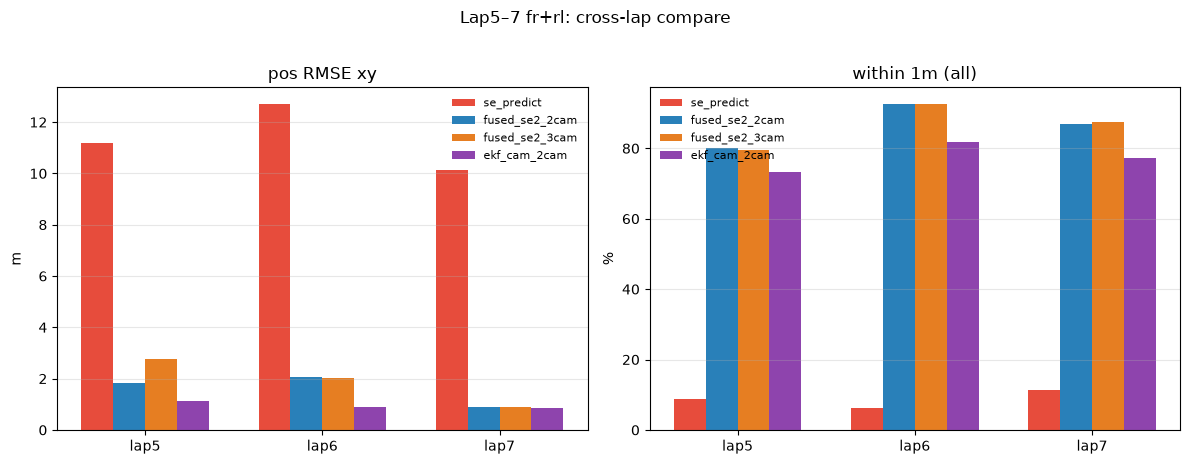

saved /Users/hbai/SchubKI/PixelRacers/query-demo/outputs/lap5_7_2cam_fr_rl/fuse_2cam_vs_3cam_cross_lap.png


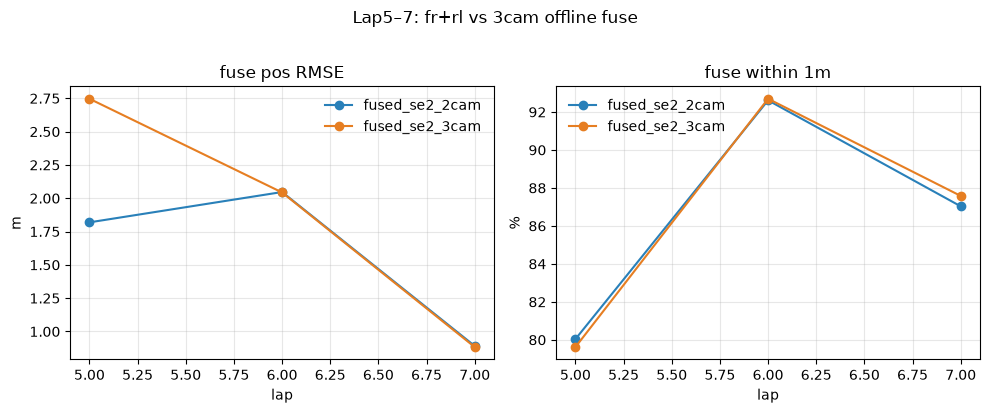

mode  se_predict  fused_se2_2cam  fused_se2_3cam  ekf_cam_2cam
lap                                                           
5         11.186           1.819           2.747         1.116
6         12.720           2.047           2.043         0.875
7         10.121           0.891           0.883         0.867


In [5]:
# grouped bar: pos RMSE / within_1m by lap × mode
modes_plot = ["se_predict", "fused_se2_2cam", "fused_se2_3cam", "ekf_cam_2cam"]
colors = {"se_predict": "#e74c3c", "fused_se2_2cam": "#2980b9",
          "fused_se2_3cam": "#e67e22", "ekf_cam_2cam": "#8e44ad"}
laps = list(LAPS)
x = np.arange(len(laps))
w = 0.18

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for i, mode in enumerate(modes_plot):
    sub = all_mdf[all_mdf["mode"] == mode].set_index("lap").reindex(laps)
    axes[0].bar(x + (i - 1.5) * w, sub["pos_rmse_xy_m"], w, label=mode, color=colors[mode])
    axes[1].bar(x + (i - 1.5) * w, sub["within_1m_%"], w, label=mode, color=colors[mode])
axes[0].set_xticks(x); axes[0].set_xticklabels([f"lap{L}" for L in laps])
axes[0].set_ylabel("m"); axes[0].set_title("pos RMSE xy"); axes[0].legend(frameon=False, fontsize=8)
axes[0].grid(True, axis="y", alpha=0.3)
axes[1].set_xticks(x); axes[1].set_xticklabels([f"lap{L}" for L in laps])
axes[1].set_ylabel("%"); axes[1].set_title("within 1m (all)"); axes[1].legend(frameon=False, fontsize=8)
axes[1].grid(True, axis="y", alpha=0.3)
fig.suptitle("Lap5–7 fr+rl: cross-lap compare", y=1.02)
fig.tight_layout()
fig.savefig(OUT_ROOT / "metrics_cross_lap.png", dpi=150, bbox_inches="tight")
print("saved", OUT_ROOT / "metrics_cross_lap.png")
plt.show()

# focused 2cam vs 3cam fuse across laps
fuse = all_mdf[all_mdf["mode"].isin(["fused_se2_2cam", "fused_se2_3cam"])].copy()
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for mode, c in [("fused_se2_2cam", "#2980b9"), ("fused_se2_3cam", "#e67e22")]:
    sub = fuse[fuse["mode"] == mode].set_index("lap").reindex(laps)
    axes[0].plot(laps, sub["pos_rmse_xy_m"], "o-", color=c, label=mode)
    axes[1].plot(laps, sub["within_1m_%"], "o-", color=c, label=mode)
axes[0].set_xlabel("lap"); axes[0].set_ylabel("m"); axes[0].set_title("fuse pos RMSE"); axes[0].legend(frameon=False); axes[0].grid(True, alpha=0.3)
axes[1].set_xlabel("lap"); axes[1].set_ylabel("%"); axes[1].set_title("fuse within 1m"); axes[1].legend(frameon=False); axes[1].grid(True, alpha=0.3)
fig.suptitle("Lap5–7: fr+rl vs 3cam offline fuse", y=1.02)
fig.tight_layout()
fig.savefig(OUT_ROOT / "fuse_2cam_vs_3cam_cross_lap.png", dpi=150, bbox_inches="tight")
print("saved", OUT_ROOT / "fuse_2cam_vs_3cam_cross_lap.png")
plt.show()

print(all_mdf.pivot(index="lap", columns="mode", values="pos_rmse_xy_m").reindex(columns=modes_plot).round(3))


## Output manifest

```
query-demo/outputs/lap5_7_2cam_fr_rl/
  metrics_all_laps.csv
  metrics_cross_lap.png
  fuse_2cam_vs_3cam_cross_lap.png
  lap{5,6,7}/
    gt_lap{N}.csv
    se_predict/  ekf_cam_2cam/  fused_se2_2cam/  fused_se2_3cam/
    compare/metrics_official.csv|.png  fuse_2cam_vs_3cam.csv|.png  traj_vs_gt.png  err_vs_time.png
```
